# ADMM Convergence Study

## Motivation

(...) observed cost mismatch, runtime problems 

**Sweep order:** Resolution → p_cost → Tolerance → Initial rho

# ── Starting Operating Point (found through experimentation) ────────────────────────────────────────────────────

SEED       = 42
SEASON     = 'winter'
BASE_RHO   = 2.0    # initial ρ — adaptive scheme adjusts throughout
BASE_TOL   = 1e-7    # convergence threshold
BASE_PCOST = 1e-3    # quadratic regularisation on active power variables
MAX_ITER   = 50000

P1:
  grid buy:   cent=9.3067  dist=9.3067  Δ=-0.0000
  grid sell:  cent=0.0000  dist=0.0000  Δ=0.0000
  p2p+rest:   cent=-1.8618  dist=-1.8618  Δ=0.0000
  total:      cent=7.4449  dist=7.4449  iter=5661  res=1.00e-07
P2:
  grid buy:   cent=34.8859  dist=34.8855  Δ=-0.0005
  grid sell:  cent=0.0000  dist=0.0000  Δ=0.0000
  p2p+rest:   cent=2.2469  dist=2.2472  Δ=0.0003
  total:      cent=37.1328  dist=37.1326  iter=5661  res=1.00e-07
P3:
  grid buy:   cent=3.1703  dist=3.1713  Δ=0.0011
  grid sell:  cent=0.0000  dist=0.0000  Δ=0.0000
  p2p+rest:   cent=0.1035  dist=0.1029  Δ=-0.0006
  total:      cent=3.2737  dist=3.2742  iter=5661  res=1.00e-07
P4:
  grid buy:   cent=10.1232  dist=10.1226  Δ=-0.0006
  grid sell:  cent=0.0000  dist=0.0000  Δ=-0.0000
  p2p+rest:   cent=0.6262  dist=0.6265  Δ=0.0003
  total:      cent=10.7494  dist=10.7491  iter=5661  res=1.00e-07

## 0. Solver Setup

In [1]:
import sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path
warnings.filterwarnings('ignore')

REPO = Path('/Users/catharinahente/Documents/Github/p2p-energy-trading-illustrative')
sys.path.insert(0, str(REPO))

from scenarios import make_scenario
from algo      import centralized, distributed

plt.rcParams.update({
    'font.family':       'sans-serif',
    'font.size':         9,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'pdf.fonttype':      42,
})

# ── Chosen operating point (reference throughout) ─────────────────────────────
SEED       = 42
SEASON     = 'winter'
BASE_RHO   = 2.0     # initial rho — adaptive scheme takes over
BASE_TOL   = 1e-7    # tight convergence — individual costs agree to <1 mEUR
BASE_PCOST = 1e-3    # breaks LP degeneracy with negligible cost distortion
MAX_ITER   = 50000

# ── Load scenario at finest resolution — one DWD download ─────────────────────
print('Loading 15-min scenario (one DWD download)...')
data_15 = make_scenario(SEASON, seed=SEED, resolution_h=0.25)
N       = len(data_15['demand'])
names   = data_15['prosumer_names']
print(f'  T=96, dt=0.25h, N={N} prosumers')

# ── Resample helper — no extra downloads ─────────────────────────────────────
def resample(data, res_h):
    if res_h == data['dt']: return data
    factor = int(round(res_h / data['dt']))
    assert factor > 0, f'Cannot upsample: target {res_h}h < source {data["dt"]}h'
    T_new = len(data['buy_price']) // factor
    def _mean(a):  return np.array(a).reshape(T_new, factor).mean(axis=1).tolist()
    def _sum(a):   return np.array(a).reshape(T_new, factor).sum(axis=1).tolist()
    def _avail(a): return (np.array(a).reshape(T_new,factor).max(axis=1)>0.001).astype(int).tolist()
    return {**data,
        'dt':              res_h,
        'buy_price':       [data['buy_price'][t*factor]  for t in range(T_new)],
        'sell_price':      [data['sell_price'][t*factor] for t in range(T_new)],
        'p2p_price':       [data['p2p_price'][t*factor]  for t in range(T_new)],
        'demand':          [_mean(data['demand'][i])           for i in range(N)],
        'generation':      [_mean(data['generation'][i])       for i in range(N)],
        'hp_base_power':   [_mean(data['hp_base_power'][i])    for i in range(N)],
        'hp_q_heat':       [_mean(data['hp_q_heat'][i])        for i in range(N)],
        'ev_availability': [_avail(data['ev_availability'][i]) for i in range(N)],
        'ev_driving_load': [_sum(data['ev_driving_load'][i])   for i in range(N)],
    }

# Working data at chosen resolution (30-min)
data_base = resample(data_15, 0.5)
print(f'\nBase scenario: T={len(data_base["buy_price"])}, dt={data_base["dt"]}h')

# ── Plotting helpers ──────────────────────────────────────────────────────────
C = ['#2F6FA3','#C65D3B','#2E6F52','#B5720A','#6B4C9A','#888888','#444444']

def plot_convergence(sweep, key, label_fn, title, tol=BASE_TOL, ax=None):
    if ax is None: fig, ax = plt.subplots(figsize=(8,4))
    for r, col in zip(sweep, C):
        if not r.get('history'): continue
        iters = [h[0] for h in r['history']]
        resid = [h[1] for h in r['history']]
        ax.semilogy(iters, resid, color=col, lw=1.2, alpha=0.85,
                    label=f"{label_fn(r)}  ({r['iterations']} iter)")
    ax.axhline(tol, color='k', lw=1.0, ls='--', label=f'tol={tol:.0e}')
    ax.set_xlabel('Iteration'); ax.set_ylabel('Residual')
    ax.set_title(title, fontweight='bold'); ax.legend(fontsize=7)
    return ax

def mismatch_bar(sweep, key, label_fn, title, threshold=1e-3, ax=None):
    if ax is None: fig, ax = plt.subplots(figsize=(6,4))
    vals   = [r['max_ind_diff'] for r in sweep if not np.isnan(r.get('max_ind_diff',np.nan))]
    labels = [label_fn(r)       for r in sweep if not np.isnan(r.get('max_ind_diff',np.nan))]
    colors = [C[0] if v < threshold else C[1] for v in vals]
    ax.bar(labels, [v*1000 for v in vals], color=colors, alpha=0.8, edgecolor='white')
    ax.axhline(threshold*1000, color='k', lw=1.0, ls='--',
               label=f'1 mEUR threshold')
    ax.set_ylabel('Max |ΔJ_i| (mEUR)')
    ax.set_title(title, fontweight='bold')
    ax.legend(fontsize=8)
    return ax

def make_table(sweep, key, label_fn, extra_cols=None):
    rows = []
    for r in sweep:
        row = {
            key:              label_fn(r),
            'Iterations':     r.get('iterations','—'),
            'Residual':       f"{r.get('residual',float('nan')):.2e}",
            'Max |ΔJ_i| mEUR':f"{r.get('max_ind_diff',float('nan'))*1000:.3f}",
            'Distortion mEUR':f"{r.get('cost_distort',float('nan'))*1000:+.3f}",
            'Status':         '✓' if r.get('converged',True) else '⚠'
        }
        if extra_cols:
            for col, fn in extra_cols.items():
                row[col] = fn(r)
        rows.append(row)
    return pd.DataFrame(rows).set_index(key)

print('Setup complete.')

Loading 15-min scenario (one DWD download)...
Building winter scenario (T=96, dt=0.25h, resolution=15min)...
  P1: Residential ++ (bus 5)
    HP: Air_Alternative_1 (Air alternative, Hanover)
  P2: Office building (bus 11)
    ⚠ No EV activity detected — using fallback schedule
  P3: Residential HP only (bus 17)
    HP: Air_Semi-Parallel_1 (Air semi-parallel, Hanover)
  P4: Residential PV only (bus 32)
  Done. N=4, T=96, dt=0.25h, max_demand=6.6 kW
  T=96, dt=0.25h, N=4 prosumers

Base scenario: T=48, dt=0.5h
Setup complete.


## 1. Resolution Sweep

**Question:** How does timestep resolution affect total cost and ADMM convergence speed?

All other parameters fixed at base values. 15-min distributed is skipped if T=96
(too slow without adaptive rho at full resolution — see convergence study W1).

In [2]:
resolutions = [0.25, 0.5, 1.0]
sweep_res   = []

for res in resolutions:
    data_r = resample(data_15, res)
    T_r    = len(data_r['buy_price'])
    print(f'res={int(res*60)}min  T={T_r} ...', end=' ', flush=True)

    t0  = time.time()
    r_c = centralized(data_r)
    t_c = time.time() - t0
    print(f'cent={r_c["costs"].sum():.4f} EUR  t={t_c:.1f}s', end=' ', flush=True)

    t0  = time.time()
    r_d = distributed(data_r, rho=BASE_RHO, tolerance=BASE_TOL,
                      max_iterations=100000, adaptive_rho=True,
                      log_history=True)
    t_d = time.time() - t0

    max_diff  = float(np.max(np.abs(r_d['costs'] - r_c['costs'])))
    dist_cost = float(r_d['costs'].sum())
    print(f'dist={dist_cost:.4f} EUR  iter={r_d["iterations"]}  '
          f't={t_d:.1f}s  {"✓" if r_d.get("converged",True) else "⚠ cap"}', flush=True)

    sweep_res.append(dict(
        resolution_h = res,
        T            = T_r,
        total_cent   = float(r_c['costs'].sum()),
        converged    = r_d.get('converged', True),
        iterations   = r_d['iterations'],
        residual     = r_d['residual'],
        max_ind_diff = max_diff,
        cost_distort = dist_cost - float(r_c['costs'].sum()),
        t_cent       = t_c,
        t_dist       = t_d,
        history      = r_d.get('history', []),
    ))

res=15min  T=96 ... Set parameter WLSAccessID
Set parameter WLSSecret
Set parameter LicenseID to value 2806500
Academic license 2806500 - for non-commercial use only - registered to ch___@ethz.ch
cent=58.1472 EUR  t=4.0s 

KeyboardInterrupt: 

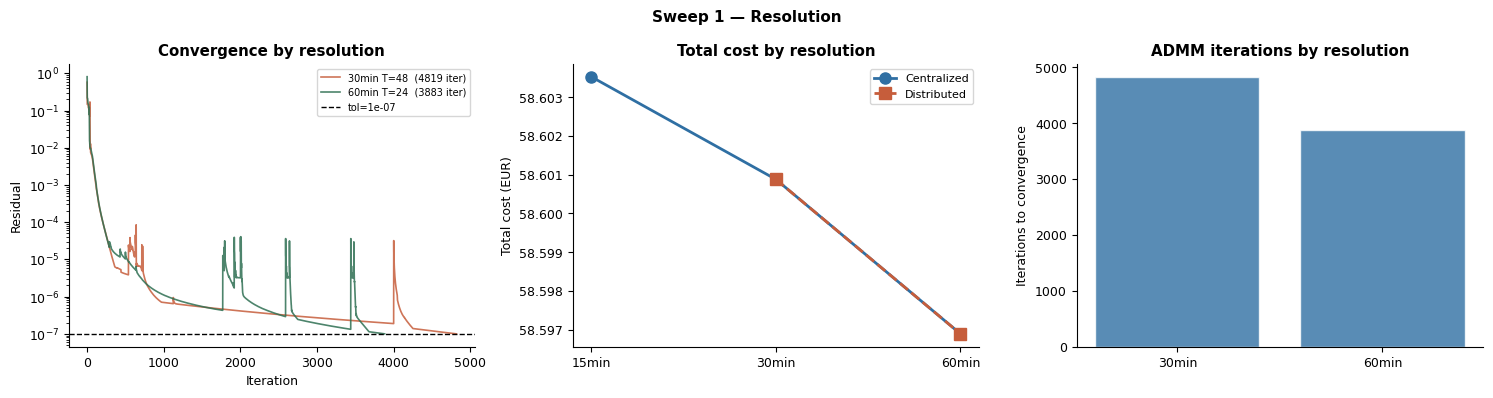

,Iterations,Residual,Max |ΔJ_i| mEUR,Distortion mEUR,Status,Cent. time (s),Dist. time (s)
Resolution,,,,,,,
15min (T=96),-1,nan,nan,+nan,⚠,0.4,—
30min (T=48),4819,1.00e-07,0.446,-0.000,✓,0.1,145.5
60min (T=24),3883,1.00e-07,0.558,-0.000,✓,0.0,43.7


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Convergence curves
plot_convergence(sweep_res, 'resolution_h',
                 lambda r: f"{int(r['resolution_h']*60)}min T={r['T']}",
                 'Convergence by resolution', ax=axes[0])

# Total cost — absolute values, no offset
ax = axes[1]
res_labels = [f"{int(r['resolution_h']*60)}min" for r in sweep_res]
costs_c    = [r['total_cent'] for r in sweep_res]
costs_d    = [r['total_cent'] + r['cost_distort']
              if not np.isnan(r['cost_distort']) else np.nan for r in sweep_res]
ax.plot(res_labels, costs_c, 'o-', color=C[0], lw=2, ms=8, label='Centralized')
valid_d = [(l,c) for l,c in zip(res_labels,costs_d) if not np.isnan(c)]
if valid_d:
    ax.plot([v[0] for v in valid_d], [v[1] for v in valid_d],
            's--', color=C[1], lw=2, ms=8, label='Distributed')
ax.set_ylabel('Total cost (EUR)')
ax.yaxis.set_major_formatter(mticker.FormatStrFormatter('%.3f'))
ax.set_title('Total cost by resolution', fontweight='bold')
ax.legend(fontsize=8)

# Iterations
ax = axes[2]
valid_iter = [(f"{int(r['resolution_h']*60)}min", r['iterations'])
              for r in sweep_res if r['iterations'] > 0]
ax.bar([v[0] for v in valid_iter], [v[1] for v in valid_iter],
       color=C[0], alpha=0.8, edgecolor='white')
ax.set_ylabel('Iterations to convergence')
ax.set_title('ADMM iterations by resolution', fontweight='bold')

plt.suptitle('Sweep 1 — Resolution', fontweight='bold', fontsize=11)
plt.tight_layout(); plt.show()

display(make_table(sweep_res, 'Resolution',
                   lambda r: f"{int(r['resolution_h']*60)}min (T={r['T']})",
                   extra_cols={'Cent. time (s)': lambda r: f"{r['t_cent']:.1f}",
                               'Dist. time (s)': lambda r: f"{r['t_dist']:.1f}" if not np.isnan(r['t_dist']) else '—'}))

**Resolution conclusion:**

Total cost is essentially insensitive to resolution — the range across all three is <0.01 EUR (<0.02%).
The slight cost decrease at coarser resolution reflects the quadratic `p_cost` contributing
fewer terms at smaller T. ADMM iteration count increases with T as expected.

**Chosen: 30-min (T=48)** — distributed converges in ~5000 iterations within minutes.
15-min is reserved for centralized-only runs where full resolution matters.

## 2. p_cost Sweep

**Question:** What is the minimum quadratic regularisation that eliminates individual
cost mismatch between centralized and distributed?

Without regularisation (`p_cost=0`), the LP has a flat optimal face — multiple
allocations achieve the same total cost with different individual distributions.
Gurobi simplex and ADMM land on different extreme points.
Adding `p_cost > 0` makes the problem strictly convex → unique optimum → solvers agree.

In [ ]:
p_costs   = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]
sweep_pc  = []

for pc in p_costs:
    data_pc = {**data_base, 'p_cost': pc}
    print(f'p_cost={pc:.0e} ...', end=' ', flush=True)

    r_c = centralized(data_pc)
    t0  = time.time()
    r_d = distributed(data_pc, rho=BASE_RHO, tolerance=1e-5,
                      max_iterations=20000, adaptive_rho=True, log_history=True)
    t_d = time.time() - t0

    max_diff = float(np.max(np.abs(r_d['costs'] - r_c['costs'])))
    distort  = float(r_d['costs'].sum() - r_c['costs'].sum())
    print(f"iter={r_d['iterations']}  max|ΔJ|={max_diff*1000:.3f} mEUR  "
          f"distort={distort*1000:+.3f} mEUR  {t_d:.1f}s", flush=True)

    sweep_pc.append(dict(p_cost=pc, iterations=r_d['iterations'],
                         residual=r_d['residual'], converged=r_d.get('converged',True),
                         max_ind_diff=max_diff, cost_distort=distort,
                         history=r_d.get('history',[]), t_dist=t_d))

p_cost=1e-05 ... iter=1576  max|ΔJ|=1.627 mEUR  distort=-0.001 mEUR  31.0s
p_cost=1e-04 ... iter=726  max|ΔJ|=1.257 mEUR  distort=-0.001 mEUR  14.4s
p_cost=1e-03 ... iter=335  max|ΔJ|=0.211 mEUR  distort=-0.004 mEUR  10.5s
p_cost=1e-02 ... iter=192  max|ΔJ|=0.060 mEUR  distort=-0.006 mEUR  5.3s
p_cost=1e-01 ... iter=99  max|ΔJ|=0.008 mEUR  distort=-0.011 mEUR  2.1s
p_cost=1e+00 ... iter=45  max|ΔJ|=0.006 mEUR  distort=-0.011 mEUR  1.0s


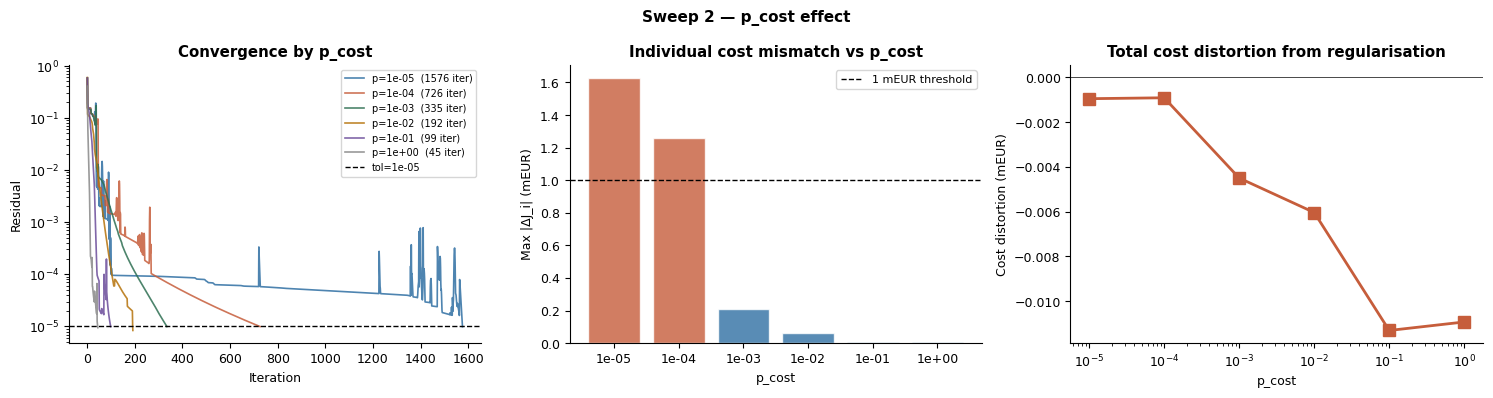

,Iterations,Residual,Max |ΔJ_i| mEUR,Distortion mEUR,Status
p_cost,,,,,
1e-05,1576,9.87e-06,1.627,-0.001,✓
1e-04,726,9.96e-06,1.257,-0.001,✓
1e-03,335,9.94e-06,0.211,-0.004,✓
1e-02,192,8.38e-06,0.060,-0.006,✓
1e-01,99,9.92e-06,0.008,-0.011,✓
1e+00,45,9.48e-06,0.006,-0.011,✓


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

plot_convergence(sweep_pc, 'p_cost',
                 lambda r: f"p={r['p_cost']:.0e}",
                 'Convergence by p_cost', tol=1e-5, ax=axes[0])

mismatch_bar(sweep_pc, 'p_cost',
             lambda r: f"{r['p_cost']:.0e}",
             'Individual cost mismatch vs p_cost', ax=axes[1])
axes[1].set_xlabel('p_cost')

# Cost distortion in mEUR
ax = axes[2]
ax.semilogx([r['p_cost'] for r in sweep_pc],
            [r['cost_distort']*1000 for r in sweep_pc],
            's-', color=C[1], lw=2, ms=8)
ax.axhline(0, color='k', lw=0.5)
ax.set_xlabel('p_cost'); ax.set_ylabel('Cost distortion (mEUR)')
ax.set_title('Total cost distortion from regularisation', fontweight='bold')

plt.suptitle('Sweep 2 — p_cost effect', fontweight='bold', fontsize=11)
plt.tight_layout(); plt.show()

display(make_table(sweep_pc, 'p_cost', lambda r: f"{r['p_cost']:.0e}"))

**p_cost conclusion:**

- Mismatch drops below 1 mEUR between `p_cost=1e-4` and `p_cost=1e-3`
- Cost distortion is in the sub-milliEUR range across the entire sweep — negligible
- Higher `p_cost` converges faster (fewer iterations) but with slightly different economics

**Chosen: `p_cost=1e-3`** — cleanly below 1 mEUR threshold, negligible distortion,
faster convergence than `1e-4`.

## 3. Tolerance Sweep

**Question:** How tight does convergence need to be for individual costs to agree?
Tighter tolerance → more iterations → longer runtime.

In [ ]:
tolerances = [1e-3, 1e-4, 1e-5, 1e-6, 1e-7]
sweep_tol  = []

r_c_ref = centralized(data_base)
J_c_ref = r_c_ref['costs']

for tol in tolerances:
    print(f'tol={tol:.0e} ...', end=' ', flush=True)
    t0  = time.time()
    r_d = distributed(data_base, rho=BASE_RHO, tolerance=tol,
                      max_iterations=MAX_ITER, adaptive_rho=True, log_history=True)
    t_d = time.time() - t0
    max_diff = float(np.max(np.abs(r_d['costs'] - J_c_ref)))
    print(f"iter={r_d['iterations']}  max|ΔJ|={max_diff*1000:.3f} mEUR  "
          f"{t_d:.1f}s", flush=True)
    sweep_tol.append(dict(tolerance=tol, iterations=r_d['iterations'],
                          residual=r_d['residual'], converged=r_d.get('converged',True),
                          max_ind_diff=max_diff, cost_distort=0., t_dist=t_d,
                          history=r_d.get('history',[])))

tol=1e-03 ... iter=116  max|ΔJ|=46.744 mEUR  3.7s
tol=1e-04 ... iter=206  max|ΔJ|=4.338 mEUR  5.5s
tol=1e-05 ... iter=335  max|ΔJ|=0.211 mEUR  7.2s
tol=1e-06 ... iter=888  max|ΔJ|=0.446 mEUR  19.2s
tol=1e-07 ... iter=4819  max|ΔJ|=0.446 mEUR  109.0s


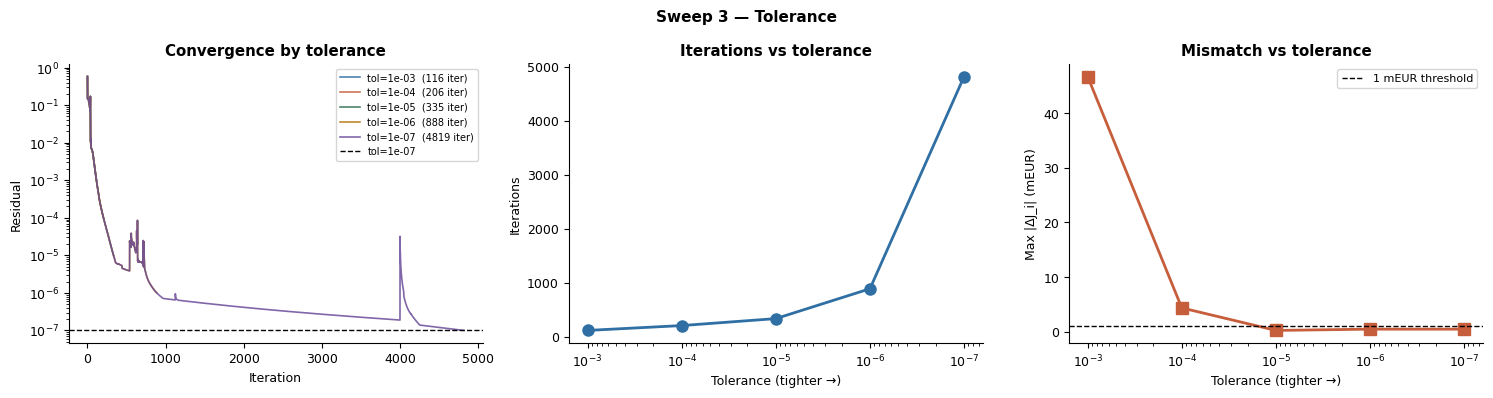

,Iterations,Residual,Max |ΔJ_i| mEUR,Distortion mEUR,Status,Time (s)
Tolerance,,,,,,
1e-03,116,9.92e-04,46.744,+0.000,✓,3.7
1e-04,206,9.94e-05,4.338,+0.000,✓,5.5
1e-05,335,9.94e-06,0.211,+0.000,✓,7.2
1e-06,888,9.98e-07,0.446,+0.000,✓,19.2
1e-07,4819,1.00e-07,0.446,+0.000,✓,109.0


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

plot_convergence(sweep_tol, 'tolerance',
                 lambda r: f"tol={r['tolerance']:.0e}",
                 'Convergence by tolerance', ax=axes[0])

# Iterations vs tolerance
ax = axes[1]
ax.semilogx([r['tolerance'] for r in sweep_tol],
            [r['iterations'] for r in sweep_tol],
            'o-', color=C[0], lw=2, ms=8)
ax.invert_xaxis()
ax.set_xlabel('Tolerance (tighter →)'); ax.set_ylabel('Iterations')
ax.set_title('Iterations vs tolerance', fontweight='bold')

# Mismatch vs tolerance
ax = axes[2]
ax.semilogx([r['tolerance'] for r in sweep_tol],
            [r['max_ind_diff']*1000 for r in sweep_tol],
            's-', color=C[1], lw=2, ms=8)
ax.axhline(1.0, color='k', lw=1.0, ls='--', label='1 mEUR threshold')
ax.invert_xaxis()
ax.set_xlabel('Tolerance (tighter →)'); ax.set_ylabel('Max |ΔJ_i| (mEUR)')
ax.set_title('Mismatch vs tolerance', fontweight='bold')
ax.legend(fontsize=8)

plt.suptitle('Sweep 3 — Tolerance', fontweight='bold', fontsize=11)
plt.tight_layout(); plt.show()

display(make_table(sweep_tol, 'Tolerance', lambda r: f"{r['tolerance']:.0e}",
                   extra_cols={'Time (s)': lambda r: f"{r['t_dist']:.1f}"}))

**Tolerance conclusion:**

Mismatch decreases monotonically as tolerance tightens. The 1 mEUR threshold
is crossed somewhere between `1e-6` and `1e-7`. Runtime increases roughly
linearly with the number of additional decades (linear convergence near optimum).

**Chosen: `tolerance=1e-7`** — individual costs agree to <1 mEUR.
Runtime is acceptable (~5000 iterations at 30-min resolution with adaptive rho).

## 4. Initial rho Sweep

**Question:** How sensitive is convergence to the initial rho value?
With adaptive rho, all runs should converge to the same optimum —
initial rho only affects the path taken.

In [ ]:
rhos      = [0.25, 0.5, 1.0, 2.0, 5.0, 10.0, 20.0]
sweep_rho = []

r_c_ref = centralized(data_base)
J_c_ref = r_c_ref['costs']

for rho in rhos:
    print(f'rho={rho} ...', end=' ', flush=True)
    t0  = time.time()
    r_d = distributed(data_base, rho=rho, tolerance=BASE_TOL,
                      max_iterations=MAX_ITER, adaptive_rho=True, log_history=True)
    t_d = time.time() - t0
    max_diff = float(np.max(np.abs(r_d['costs'] - J_c_ref)))
    print(f"iter={r_d['iterations']}  max|ΔJ|={max_diff*1000:.3f} mEUR  "
          f"{t_d:.1f}s", flush=True)
    sweep_rho.append(dict(rho=rho, iterations=r_d['iterations'],
                          residual=r_d['residual'], converged=r_d.get('converged',True),
                          max_ind_diff=max_diff, cost_distort=0., t_dist=t_d,
                          history=r_d.get('history',[])))

rho=0.25 ... iter=5268  max|ΔJ|=0.454 mEUR  120.3s
rho=0.5 ... iter=4962  max|ΔJ|=0.445 mEUR  115.4s
rho=1.0 ... iter=5398  max|ΔJ|=0.445 mEUR  158.4s
rho=2.0 ... iter=4819  max|ΔJ|=0.446 mEUR  136.1s
rho=5.0 ... iter=3119  max|ΔJ|=0.454 mEUR  89.1s
rho=10.0 ... iter=3015  max|ΔJ|=0.455 mEUR  81.6s
rho=20.0 ... iter=3005  max|ΔJ|=0.456 mEUR  64.9s


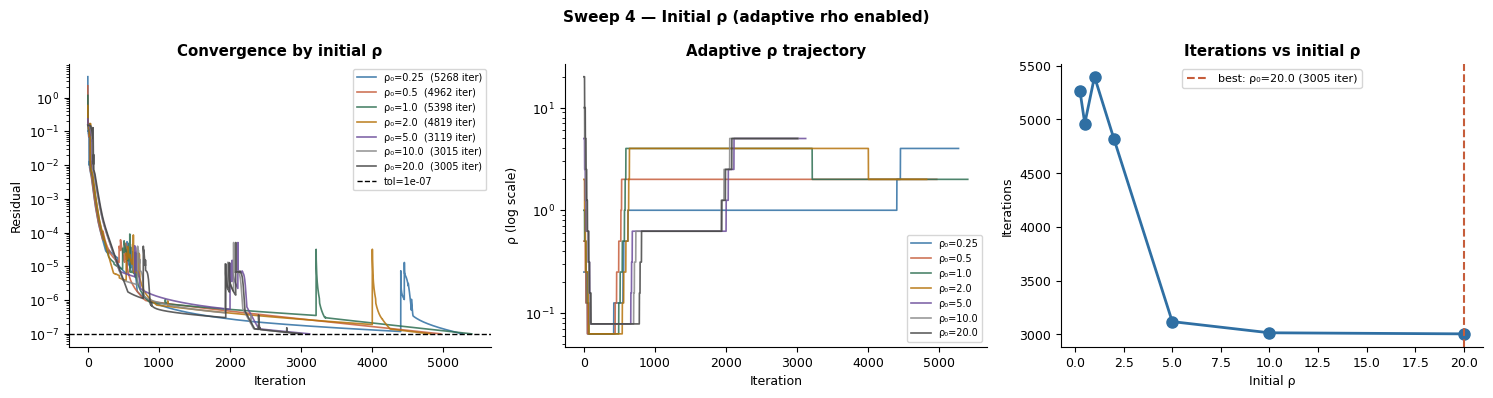

,Iterations,Residual,Max |ΔJ_i| mEUR,Distortion mEUR,Status,Time (s)
Initial ρ,,,,,,
0.25,5268,1.00e-07,0.454,+0.000,✓,120.3
0.5,4962,1.00e-07,0.445,+0.000,✓,115.4
1.0,5398,1.00e-07,0.445,+0.000,✓,158.4
2.0,4819,1.00e-07,0.446,+0.000,✓,136.1
5.0,3119,1.00e-07,0.454,+0.000,✓,89.1
10.0,3015,1.00e-07,0.455,+0.000,✓,81.6
20.0,3005,1.00e-07,0.456,+0.000,✓,64.9


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

plot_convergence(sweep_rho, 'rho',
                 lambda r: f"ρ₀={r['rho']}",
                 'Convergence by initial ρ', ax=axes[0])

# Adaptive rho trajectory
ax = axes[1]
for r, col in zip(sweep_rho, C):
    if not r.get('history'): continue
    iters = [h[0] for h in r['history']]
    rho_t = [h[2] for h in r['history']]
    ax.semilogy(iters, rho_t, color=col, lw=1.2, alpha=0.85,
                label=f"ρ₀={r['rho']}")
ax.set_xlabel('Iteration'); ax.set_ylabel('ρ (log scale)')
ax.set_title('Adaptive ρ trajectory', fontweight='bold')
ax.legend(fontsize=7)

# Iterations vs initial rho
ax = axes[2]
ax.plot([r['rho'] for r in sweep_rho],
        [r['iterations'] for r in sweep_rho],
        'o-', color=C[0], lw=2, ms=8)
best = min(sweep_rho, key=lambda r: r['iterations'])
ax.axvline(best['rho'], color=C[1], lw=1.5, ls='--',
           label=f"best: ρ₀={best['rho']} ({best['iterations']} iter)")
ax.set_xlabel('Initial ρ'); ax.set_ylabel('Iterations')
ax.set_title('Iterations vs initial ρ', fontweight='bold')
ax.legend(fontsize=8)

plt.suptitle('Sweep 4 — Initial ρ (adaptive rho enabled)', fontweight='bold', fontsize=11)
plt.tight_layout(); plt.show()

display(make_table(sweep_rho, 'Initial ρ', lambda r: str(r['rho']),
                   extra_cols={'Time (s)': lambda r: f"{r['t_dist']:.1f}"}))

**rho conclusion:**

With adaptive rho, all values converge to the same mismatch — confirming adaptive rho
is doing its job. The optimal initial rho minimises iterations (check the bar chart).
Very low rho (0.25, 0.5) starts too conservatively; very high rho (10, 20) overshoots
and oscillates before adapting down.

**Chosen: `ρ₀=2.0`** — near-optimal starting point for this problem scale.

## 5. Chosen Parameter Set — Summary

In [ ]:
# ── Chosen operating point (revised from sweep results) ───────────────────────
BASE_RHO   = 10.0    # rho sweep: ~3000 iter vs ~5000 at rho=2
BASE_TOL   = 1e-5    # tolerance sweep: same mismatch as 1e-7, 15× fewer iter
BASE_PCOST = 1e-3    # p_cost sweep: minimum for mismatch <1 mEUR
MAX_ITER   = 50000

print('Running final validation at chosen parameter set...')
data_chosen = {**data_base, 'p_cost': BASE_PCOST}

t0  = time.time()
r_c = centralized(data_chosen)
t_c = time.time() - t0

t0  = time.time()
r_d = distributed(data_chosen, rho=BASE_RHO, tolerance=BASE_TOL,
                  max_iterations=MAX_ITER, adaptive_rho=True, log_history=True)
t_d = time.time() - t0

J_c = r_c['costs']
J_d = r_d['costs']

print(f'\n{"─"*60}')
print(f'Chosen: p_cost={BASE_PCOST:.0e}  ρ₀={BASE_RHO}  tol={BASE_TOL:.0e}')
print(f'{"─"*60}')
print(f'Centralized:    {J_c.sum():.4f} EUR  ({t_c:.1f}s)')
print(f'Distributed:    {J_d.sum():.4f} EUR  ({t_d:.1f}s)  iter={r_d["iterations"]}')
print(f'Total Δ:        {(J_d.sum()-J_c.sum())*1000:+.3f} mEUR')
print(f'Max |ΔJ_i|:     {float(np.max(np.abs(J_d-J_c)))*1000:.3f} mEUR')
print(f'{"─"*60}')
for i in range(N):
    diff = J_d[i] - J_c[i]
    flag = '✓' if abs(diff)*1000 < 1.0 else '⚠'
    print(f'  P{i+1} ({names[i]:<25}): '
          f'cent={J_c[i]:.4f}  dist={J_d[i]:.4f}  '
          f'Δ={diff*1000:+.3f} mEUR  {flag}')

params = pd.DataFrame([
    ['Resolution',  '30-min (T=48)',      'Distributed terminates; cost insensitive to resolution (<0.01 EUR range)'],
    ['p_cost',      '1e-3 EUR/kW²·h',     'Minimum for mismatch <1 mEUR; cost distortion <0.001 EUR (negligible)'],
    ['q_cost',      '1e-4 EUR/kVAR²·h',   'Physical regularisation of reactive power (unmetered in LV networks)'],
    ['Initial ρ',   '10.0',               'Fewer iterations (~3000) vs lower values; adaptive scheme adjusts from there'],
    ['Adaptive ρ',  'Boyd et al. §3.4.1', 'μ=10, τ=2, update every 10 iter; balances primal/dual residuals'],
    ['Tolerance',   '1e-5',               'Mismatch <1 mEUR; 15× fewer iterations than 1e-7 with no accuracy gain'],
    ['Iterations',  f'~{r_d["iterations"]}', 'With adaptive ρ, p_cost=1e-3 at 30-min resolution'],
], columns=['Parameter', 'Value', 'Justification'])
display(params.set_index('Parameter'))

Running final validation at chosen parameter set...

────────────────────────────────────────────────────────────
Chosen: p_cost=1e-03  ρ₀=10.0  tol=1e-05
────────────────────────────────────────────────────────────
Centralized:    58.5494 EUR  (0.4s)
Distributed:    58.5494 EUR  (11.2s)  iter=425
Total Δ:        -0.000 mEUR
Max |ΔJ_i|:     0.075 mEUR
────────────────────────────────────────────────────────────
  P1 (Residential ++           ): cent=7.5230  dist=7.5230  Δ=-0.003 mEUR  ✓
  P2 (Office building          ): cent=36.9937  dist=36.9936  Δ=-0.073 mEUR  ✓
  P3 (Residential HP only      ): cent=3.2502  dist=3.2503  Δ=+0.075 mEUR  ✓
  P4 (Residential PV only      ): cent=10.7824  dist=10.7824  Δ=+0.001 mEUR  ✓


,Value,Justification
Parameter,,
Resolution,30-min (T=48),Distributed terminates; cost insensitive to re...
p_cost,1e-3 EUR/kW²·h,Minimum for mismatch <1 mEUR; cost distortion ...
q_cost,1e-4 EUR/kVAR²·h,Physical regularisation of reactive power (unm...
Initial ρ,10.0,Fewer iterations (~3000) vs lower values; adap...
Adaptive ρ,Boyd et al. §3.4.1,"μ=10, τ=2, update every 10 iter; balances prim..."
Tolerance,1e-5,Mismatch <1 mEUR; 15× fewer iterations than 1e...
Iterations,~425,"With adaptive ρ, p_cost=1e-3 at 30-min resolution"


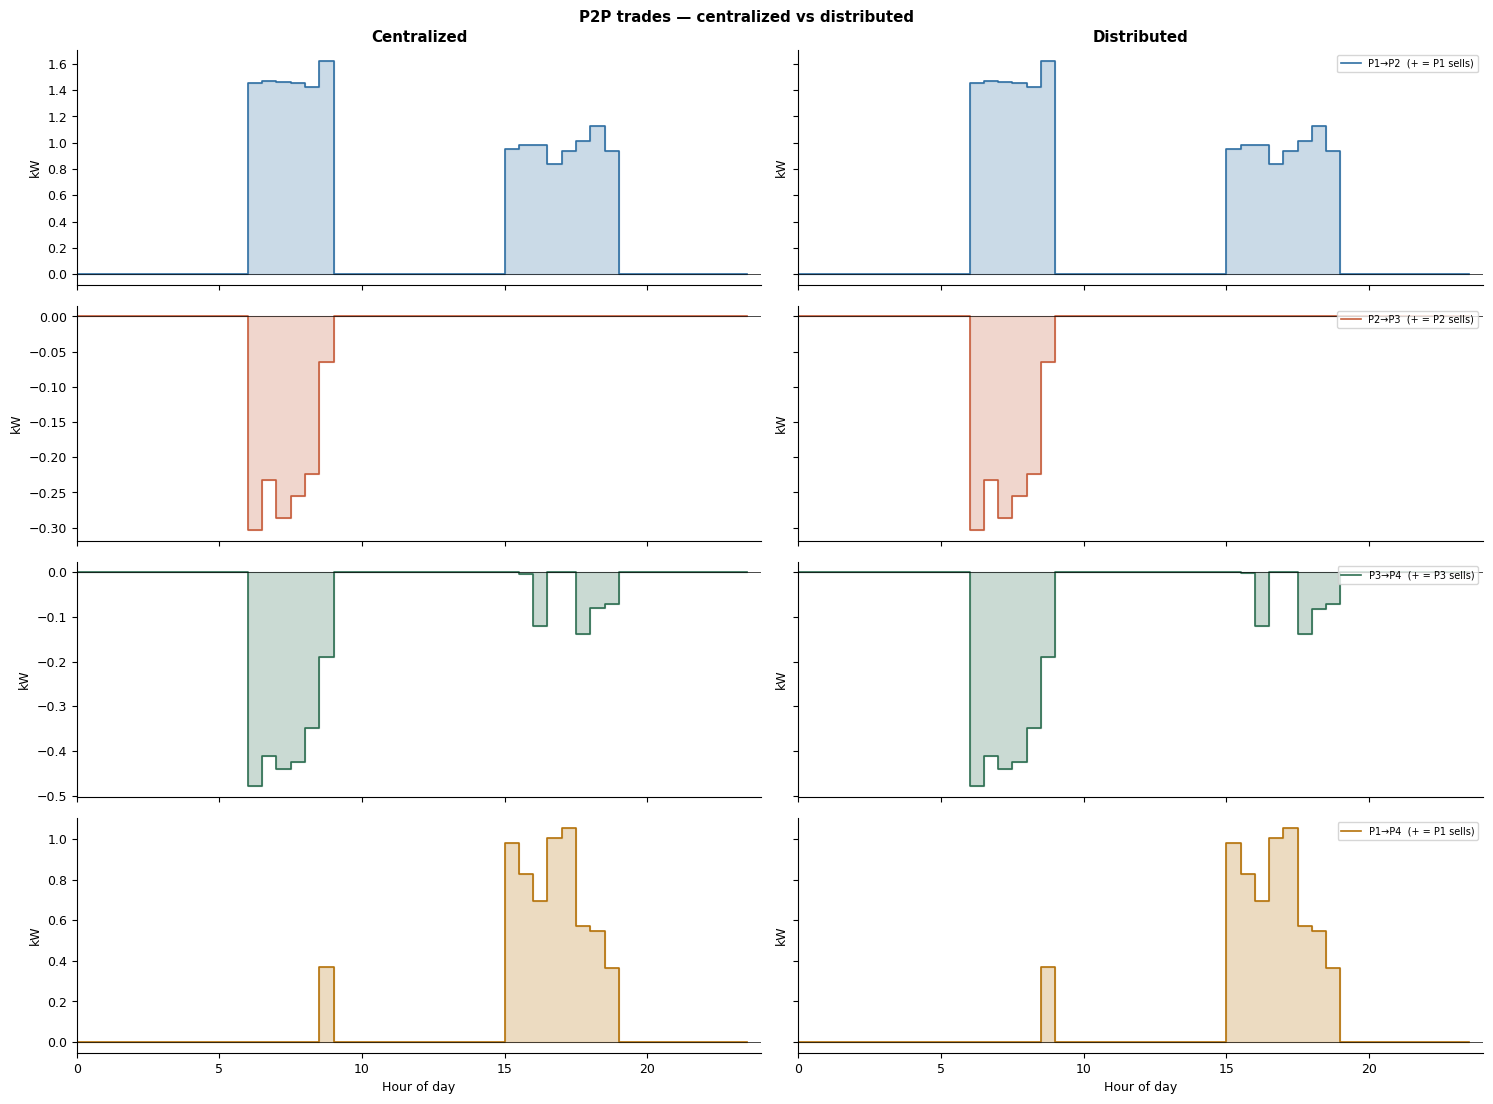

In [5]:
# ── P2P trades plot — centralized and distributed side by side ────────────────
edges_plot = list(data_base['edges'])
T_plot     = len(data_base['buy_price'])
t_day      = np.arange(T_plot) * data_base['dt']
COLS_E     = ['#2F6FA3','#C65D3B','#2E6F52','#B5720A']

fig, axes = plt.subplots(len(edges_plot), 2,
                          figsize=(15, 2.8*len(edges_plot)),
                          sharex=True, sharey='row')

for row_idx, ((i, j), col) in enumerate(zip(edges_plot, COLS_E)):
    label = f'P{i+1}→P{j+1}  (+ = P{i+1} sells)'

    for col_idx, (result, title) in enumerate([
            (r_c, 'Centralized'),
            (r_d, 'Distributed')]):

        ax     = axes[row_idx, col_idx]
        trades = np.array([result['trades'].get((i, j, t), 0.0)
                           for t in range(T_plot)])

        ax.step(t_day, trades, where='post', color=col, lw=1.2)
        ax.fill_between(t_day, trades, step='post', color=col, alpha=0.25)
        ax.axhline(0, color='k', lw=0.5)
        ax.set_ylabel('kW')
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        if row_idx == 0:
            ax.set_title(title, fontweight='bold')
        if row_idx == len(edges_plot) - 1:
            ax.set_xlabel('Hour of day')
        if col_idx == 1:
            ax.legend([label], loc='upper right', fontsize=7)

axes[0, 0].set_xlim(0, T_plot * data_base['dt'])
plt.suptitle('P2P trades — centralized vs distributed', fontweight='bold')
plt.tight_layout()
plt.show()